In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Fertilizer Prediction.csv')
df.head()

,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26,52,38,Sandy,Maize,37,0,0,Urea
1,29,52,45,Loamy,Sugarcane,12,0,36,DAP
2,34,65,62,Black,Cotton,7,9,30,14-35-14
3,32,62,34,Red,Tobacco,22,0,20,28-28
4,28,54,46,Clayey,Paddy,35,0,0,Urea


In [3]:
df.shape

(99, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Temparature      99 non-null     int64
 1   Humidity         99 non-null     int64
 2   Moisture         99 non-null     int64
 3   Soil Type        99 non-null     str  
 4   Crop Type        99 non-null     str  
 5   Nitrogen         99 non-null     int64
 6   Potassium        99 non-null     int64
 7   Phosphorous      99 non-null     int64
 8   Fertilizer Name  99 non-null     str  
dtypes: int64(6), str(3)
memory usage: 8.7 KB


In [5]:
df.describe(include='all')

,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
count,99.000000,99.000000,99.000000,99,99,99.000000,99.000000,99.000000,99
unique,NaN,NaN,NaN,5,11,NaN,NaN,NaN,7
top,NaN,NaN,NaN,Loamy,Sugarcane,NaN,NaN,NaN,Urea
freq,NaN,NaN,NaN,21,13,NaN,NaN,NaN,22
mean,30.282828,59.151515,43.181818,NaN,NaN,18.909091,3.383838,18.606061,NaN
std,3.502304,5.840331,11.271568,NaN,NaN,11.599693,5.814667,13.476978,NaN
min,25.000000,50.000000,25.000000,NaN,NaN,4.000000,0.000000,0.000000,NaN
25%,28.000000,54.000000,34.000000,NaN,NaN,10.000000,0.000000,9.000000,NaN
50%,30.000000,60.000000,41.000000,NaN,NaN,13.000000,0.000000,19.000000,NaN
75%,33.000000,64.000000,50.500000,NaN,NaN,24.000000,7.500000,30.000000,NaN


In [6]:
df.isnull().sum()

Temparature        0
Humidity           0
Moisture           0
Soil Type          0
Crop Type          0
Nitrogen           0
Potassium          0
Phosphorous        0
Fertilizer Name    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.dtypes

Temparature        int64
Humidity           int64
Moisture           int64
Soil Type            str
Crop Type            str
Nitrogen           int64
Potassium          int64
Phosphorous        int64
Fertilizer Name      str
dtype: object

In [9]:
df.columns

Index(['Temparature', 'Humidity ', 'Moisture', 'Soil Type', 'Crop Type',
       'Nitrogen', 'Potassium', 'Phosphorous', 'Fertilizer Name'],
      dtype='str')

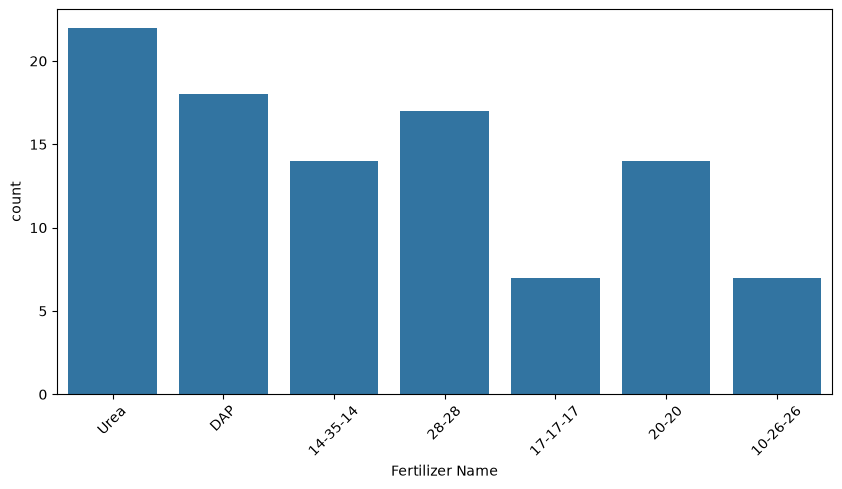

In [10]:
# Target Distribution
plt.figure(figsize=(10,5))
sns.countplot(
    x="Fertilizer Name",
    data=df
)
plt.xticks(rotation=45)
plt.show()

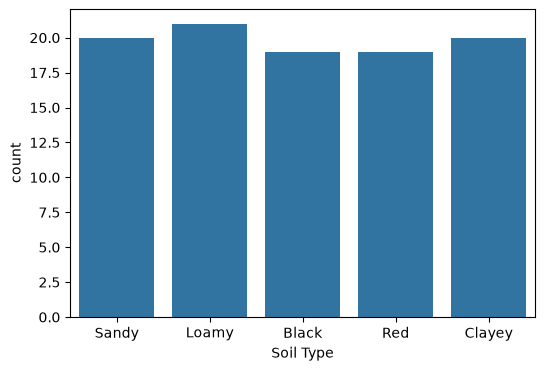

In [11]:
# Soil type distribution
plt.figure(figsize=(6,4))
sns.countplot(
    x="Soil Type",
    data=df
)
plt.show()

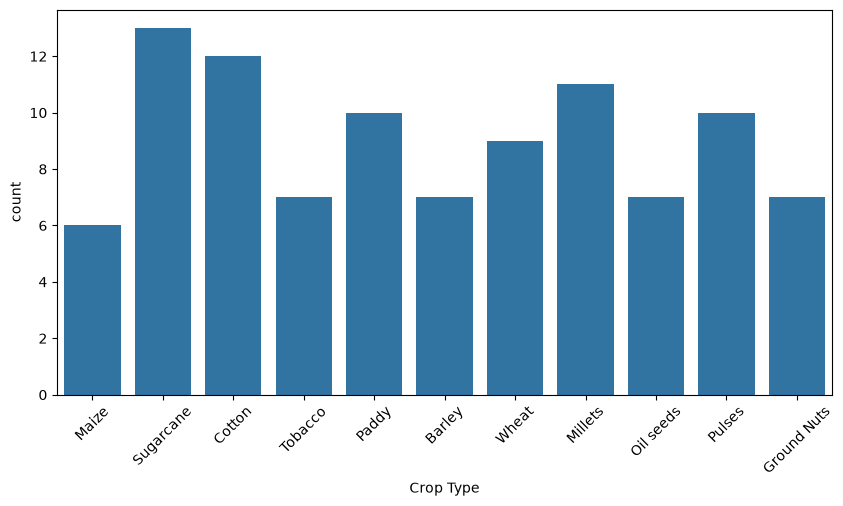

In [12]:
# Crop type Distribution
plt.figure(figsize=(10,5))
sns.countplot(
    x="Crop Type",
    data=df
)
plt.xticks(rotation=45)
plt.show()

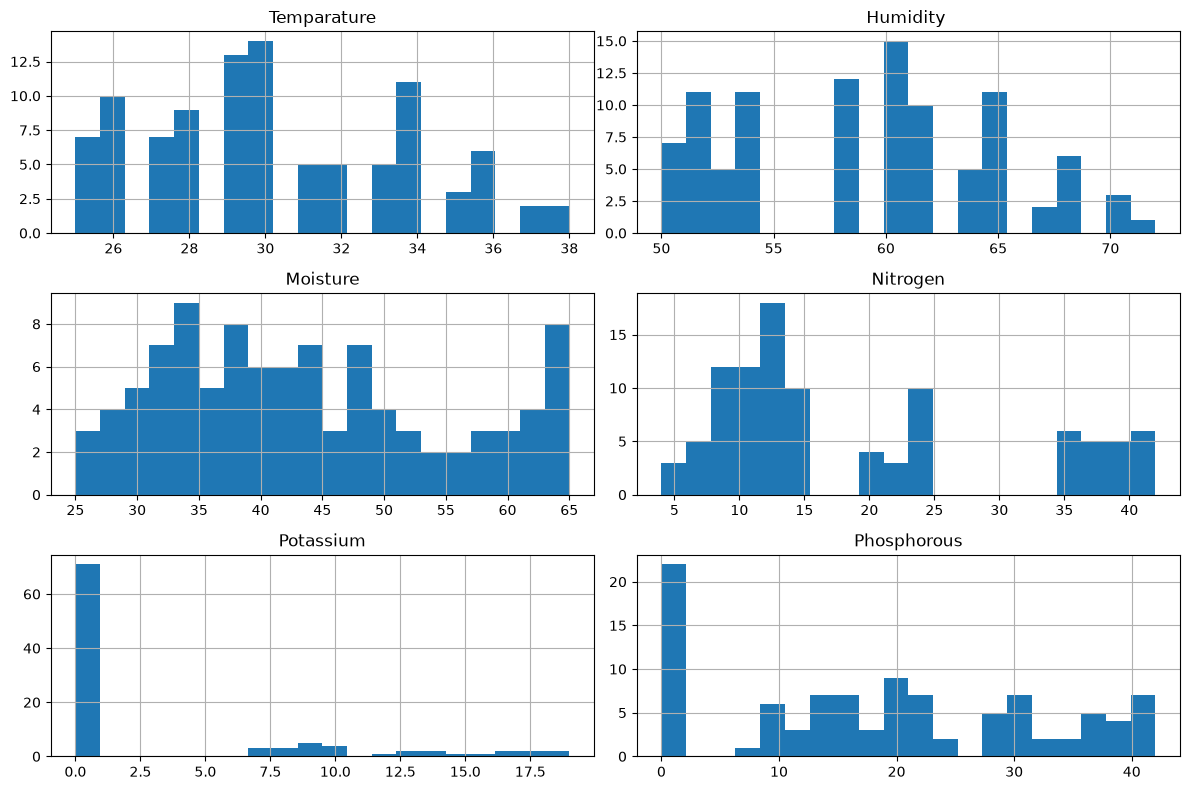

In [14]:
# Numerical Feature Distribution
numerical_cols = [
    "Temparature",
    "Humidity ",
    "Moisture",
    "Nitrogen",
    "Potassium",
    "Phosphorous"
]
df[numerical_cols].hist(
    figsize=(12,8),
    bins=20
)
plt.tight_layout()
plt.show()

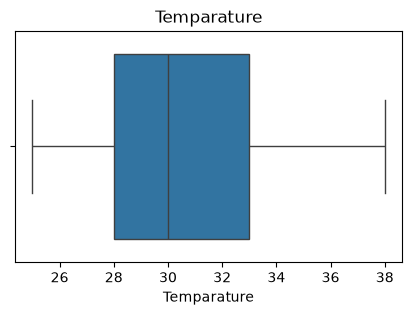

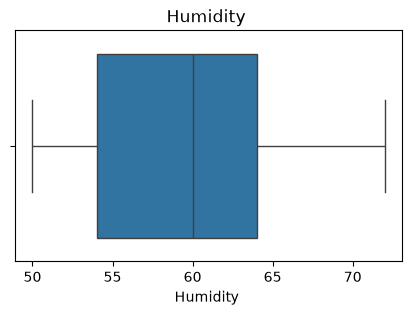

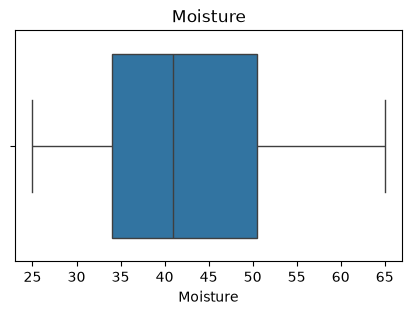

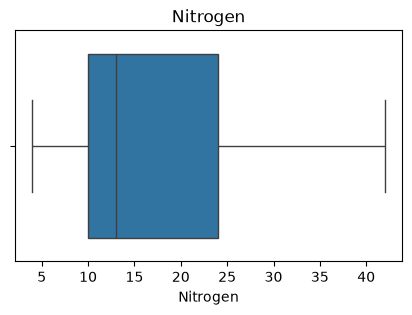

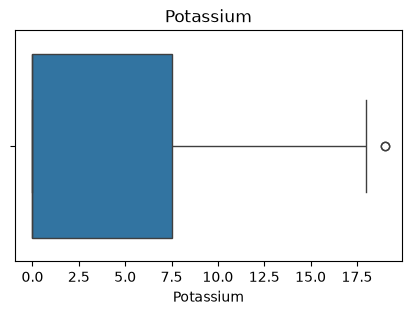

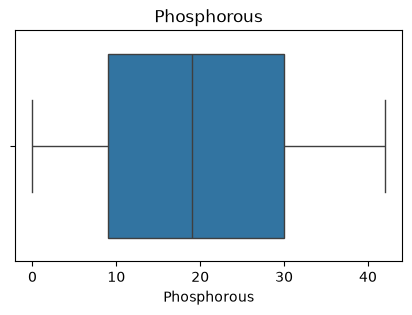

In [15]:
# Boxplots
for col in numerical_cols:
    plt.figure(figsize=(5,3))
    sns.boxplot(
        x=df[col]
    )
    plt.title(col)
    plt.show()

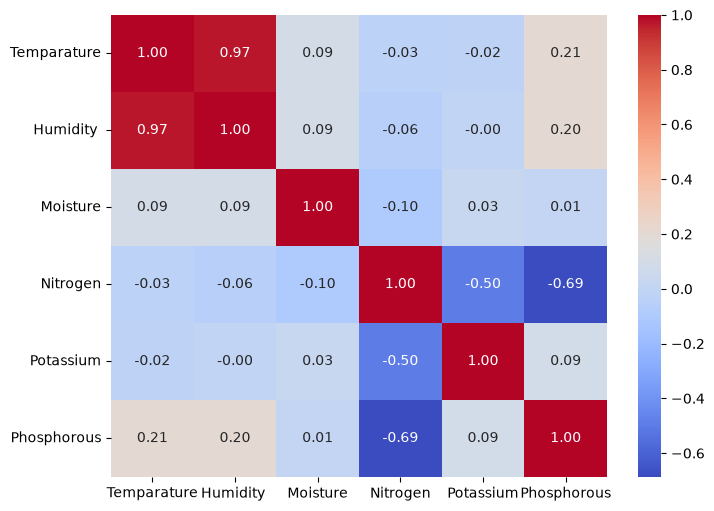

In [16]:
# Correlation Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(
    df[numerical_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.show()

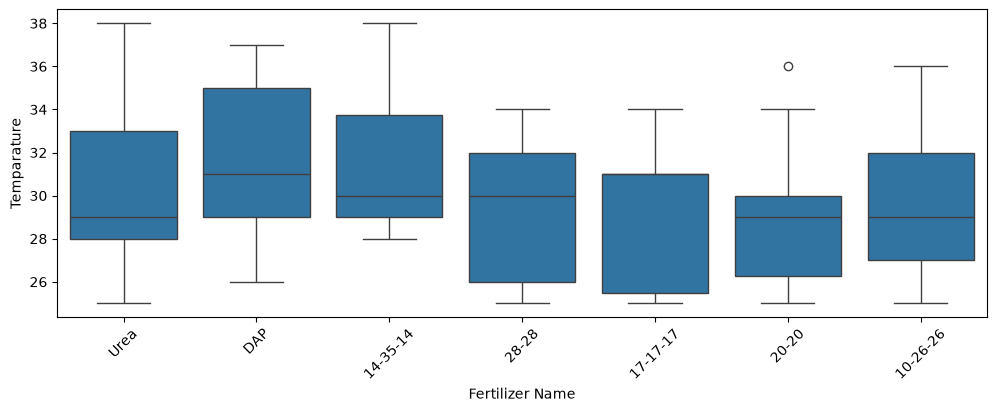

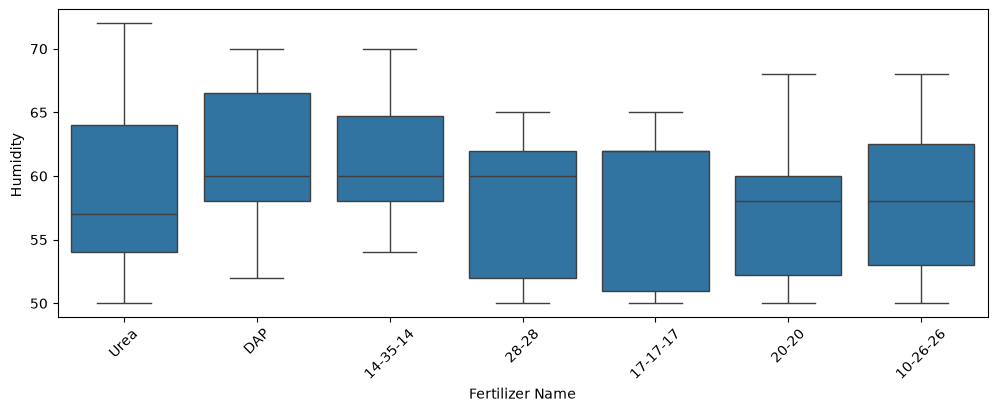

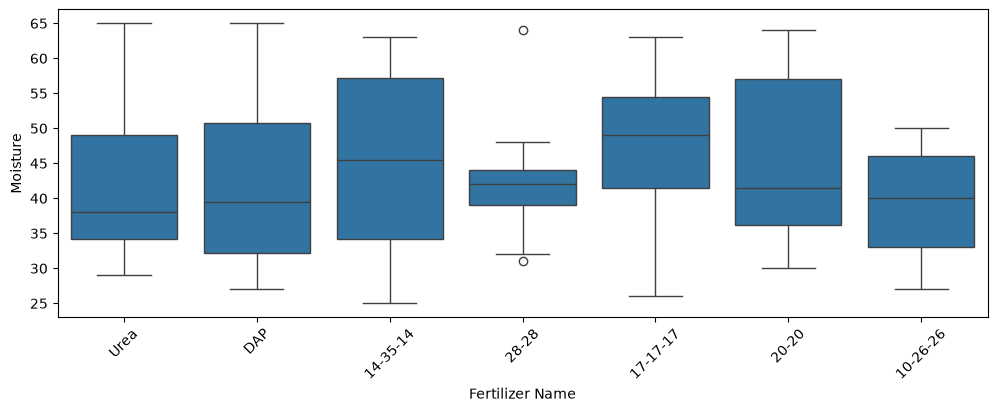

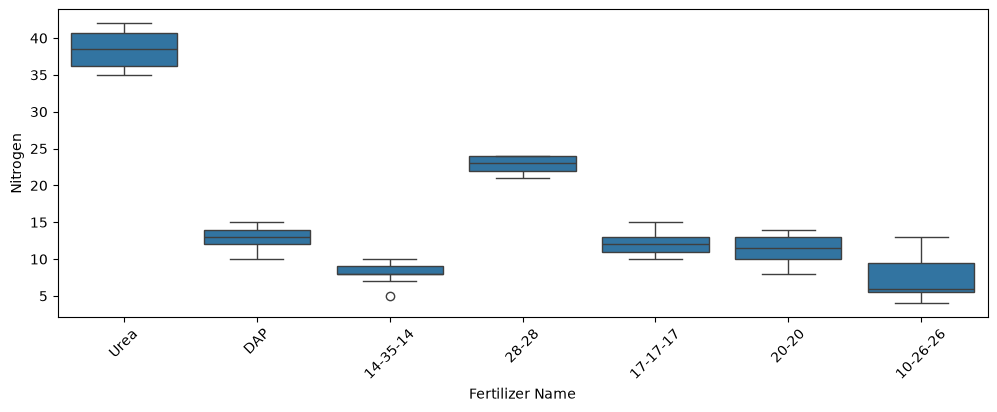

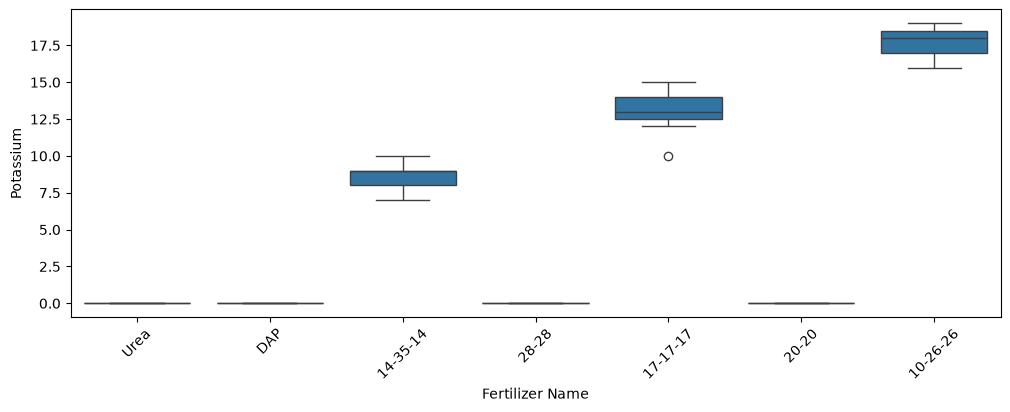

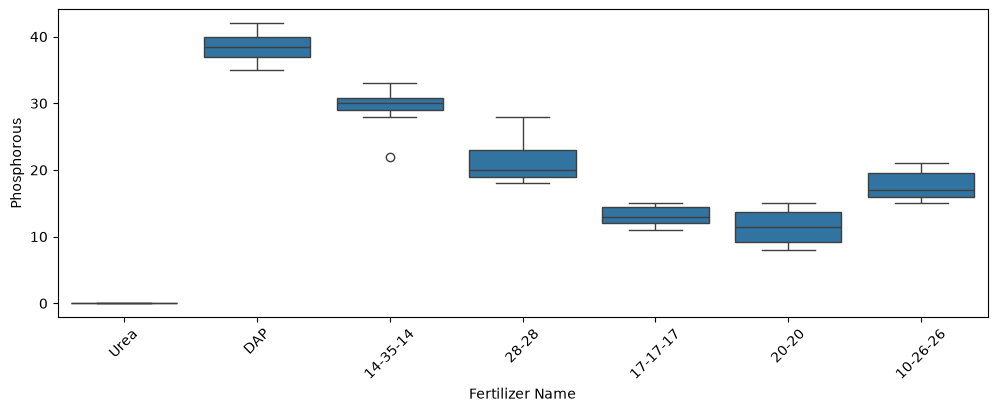

In [17]:
# Relationship Between Fertilizer and Numerical Features
for col in numerical_cols:
    plt.figure(figsize=(12,4))
    sns.boxplot(
        x="Fertilizer Name",
        y=col,
        data=df
    )
    plt.xticks(rotation=45)
    plt.show()

In [18]:
# Soil Type vs Fertilizer
pd.crosstab(
    df["Soil Type"],
    df["Fertilizer Name"]
)

Fertilizer Name,10-26-26,14-35-14,17-17-17,20-20,28-28,DAP,Urea
Soil Type,,,,,,,
Black,0,3,1,4,2,2,7
Clayey,3,3,0,3,4,2,5
Loamy,1,4,2,3,2,4,5
Red,2,1,2,1,4,6,3
Sandy,1,3,2,3,5,4,2


In [19]:
# Crop Type vs Fertilizer
pd.crosstab(
    df["Crop Type"],
    df["Fertilizer Name"]
)

Fertilizer Name,10-26-26,14-35-14,17-17-17,20-20,28-28,DAP,Urea
Crop Type,,,,,,,
Barley,1,1,1,0,2,2,0
Cotton,0,3,1,1,1,4,2
Ground Nuts,0,0,1,0,1,3,2
Maize,0,2,1,0,2,0,1
Millets,0,0,0,3,2,2,4
Oil seeds,0,2,0,2,0,1,2
Paddy,1,2,0,1,2,1,3
Pulses,2,1,0,2,2,1,2
Sugarcane,0,2,3,4,0,2,2


In [20]:
# Feature & Target
X = df.drop("Fertilizer Name", axis=1)
y = df["Fertilizer Name"]

In [21]:
# Label Encoding
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
y = encoder.fit_transform(y)

In [22]:
# Train Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [23]:
# Define Columns
categorical_features = [
    "Soil Type",
    "Crop Type"
]

numeric_features = [
    "Temparature",
    "Humidity ",
    "Moisture",
    "Nitrogen",
    "Potassium",
    "Phosphorous"
]

In [24]:
import time
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

In [25]:
# Preprocess
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numeric_features
        )
    ]

)

In [26]:
# Pipelines
models = {

    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "KNN": Pipeline([
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier())
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(random_state=42))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(
            random_state=42,
            eval_metric="mlogloss"
        ))
    ])

}

In [27]:
# Model Evaluation Function
def evaluate_models(models, X_train, X_test, y_train, y_test):

    results = []
    trained_models = {}
    for name, model in models.items():
        train_start = time.time()
        model.fit(X_train, y_train)
        train_time = time.time() - train_start

        pred_start = time.time()
        y_pred = model.predict(X_test)
        pred_time = time.time() - pred_start

        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(X_test)

            roc_auc = roc_auc_score(
                y_test,
                y_prob,
                multi_class="ovr",
                average="weighted"
            )
        else:
            roc_auc = np.nan

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, average="weighted")
        recall = recall_score(y_test, y_pred, average="weighted")
        f1 = f1_score(y_test, y_pred, average="weighted")

        trained_models[name] = model

        results.append({
            "Model": name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1,
            "ROC-AUC": roc_auc,
            "Train Time (s)": train_time,
            "Prediction Time (s)": pred_time
        })

        print("="*70)
        print(name)
        print("="*70)

        print(classification_report(y_test, y_pred))
        print(confusion_matrix(y_test, y_pred))

    results = pd.DataFrame(results)

    results = results.sort_values(
        by=["Accuracy", "Prediction Time (s)"],
        ascending=[False, True]
    )

    return results, trained_models

In [28]:
results, trained_models = evaluate_models(
    models,
    X_train,
    X_test,
    y_train,
    y_test
)

results

C:\Users\Hp\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         1
           3       1.00      1.00      1.00         3
           4       1.00      1.00      1.00         3
           5       1.00      1.00      1.00         4
           6       1.00      1.00      1.00         5

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20

[[1 0 0 0 0 0 0]
 [0 3 0 0 0 0 0]
 [0 0 1 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 3 0 0]
 [0 0 0 0 0 4 0]
 [0 0 0 0 0 0 5]]


C:\Users\Hp\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Hp\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Hp\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

KNN
              precision    recall  f1-score   support

           0       0.25      1.00      0.40         1
           1       1.00      0.33      0.50         3
           2       0.00      0.00      0.00         1
           3       1.00      1.00      1.00         3
           4       1.00      1.00      1.00         3
           5       1.00      1.00      1.00         4
           6       1.00      1.00      1.00         5

    accuracy                           0.85        20
   macro avg       0.75      0.76      0.70        20
weighted avg       0.91      0.85      0.84        20

[[1 0 0 0 0 0 0]
 [2 1 0 0 0 0 0]
 [1 0 0 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 3 0 0]
 [0 0 0 0 0 4 0]
 [0 0 0 0 0 0 5]]
Decision Tree
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      0.67      0.80         3
           2       0.50      1.00      0.67         1
           3       1.00      1.00      1.00     

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Train Time (s),Prediction Time (s)
0,Logistic Regression,1.00,1.0000,1.00,1.000000,1.000000,1.179449,0.009356
4,XGBoost,1.00,1.0000,1.00,1.000000,1.000000,0.191025,0.016399
3,Random Forest,1.00,1.0000,1.00,1.000000,1.000000,0.297924,0.018949
2,Decision Tree,0.95,0.9750,0.95,0.953333,0.973684,0.013651,0.007711
1,KNN,0.85,0.9125,0.85,0.845000,0.993111,0.012995,4.031149


In [29]:
# Cross Validation
def cross_validation(models, X, y):

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )
    scores = []
    for name, model in models.items():
        accuracy = cross_val_score(
            model,
            X,
            y,
            cv=cv,
            scoring="accuracy",
            n_jobs=-1
        )
        scores.append({

            "Model": name,
            "Mean Accuracy": accuracy.mean(),
            "Std": accuracy.std()

        })

    return pd.DataFrame(scores).sort_values(
        by="Mean Accuracy",
        ascending=False
    )

In [30]:
cv_results = cross_validation(models, X, y)
cv_results

,Model,Mean Accuracy,Std
0,Logistic Regression,1.000000,0.000000
2,Decision Tree,0.980000,0.024495
4,XGBoost,0.960000,0.037417
3,Random Forest,0.930000,0.050990
1,KNN,0.908947,0.037756


In [31]:
# Hyperparameter Tunning
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

In [32]:
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["lbfgs", "liblinear"],
    "model__penalty": ["l2"]
}

In [33]:
grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
grid.fit(X_train, y_train)

C:\Users\Hp\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,estimator,Pipeline(step..._iter=1000))])
,param_grid,"{'model__C': [0.01, 0.1, ...], 'model__penalty': ['l2'], 'model__solver': ['lbfgs', 'liblinear']}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('cat', ...), ('num', ...)]"


In [34]:
print(grid.best_params_)
print(grid.best_score_)

{'model__C': 0.1, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
0.9875


In [35]:
best_pipeline = grid.best_estimator_

joblib.dump(best_pipeline, "fertilizer_pipeline.pkl")
joblib.dump(encoder, "fertilizer_label_encoder.pkl")

['fertilizer_label_encoder.pkl']

In [43]:
# Test Prediction
pipeline = joblib.load("fertilizer_pipeline.pkl")
encoder = joblib.load("fertilizer_label_encoder.pkl")

sample = pd.DataFrame({
    "Temparature": [29],
    "Humidity ": [10],
    "Moisture": [90],
    "Soil Type": ["Loamy"],
    "Crop Type": ["Wheat"],
    "Nitrogen": [74],
    "Potassium": [0],
    "Phosphorous": [36]
})

prediction = pipeline.predict(sample)

fertilizer = encoder.inverse_transform(prediction)

print(fertilizer[0])

28-28
